# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal de clasificación con **Keras 3**.

En este ejercicio vas a aplicar la misma receta sobre un dataset diferente:

> **Olivetti Faces**

El dataset contiene imágenes de rostros en escala de grises. El objetivo será identificar a cuál persona pertenece cada imagen.

No necesitas diseñar un pipeline de datos nuevo. La carga, división y visualización están resueltas.

Tu trabajo se concentra en completar las etapas principales de Keras:

```text
Datos
  ↓
Modelo
  ↓
Loss + Optimizer
  ↓
Entrenamiento
  ↓
Evaluación
  ↓
Predicción
```

---

## ¿Qué debes completar?

Las celdas marcadas con `# TODO` contienen espacios que debes completar.

El resto del código está preparado para que puedas concentrarte en los conceptos vistos en clase.


---
## 0. Importar librerías

Usaremos:

- **Keras 3** para construir y entrenar la red.
- **scikit-learn** para cargar Olivetti Faces y dividir los datos.
- **NumPy** para manipular arrays.
- **Matplotlib** para visualizar imágenes.


In [1]:
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.13.2
Backend       : tensorflow


---
# 1. Dataset: Olivetti Faces

Olivetti Faces contiene:

- **400 imágenes**
- imágenes de **64 × 64 píxeles**
- escala de grises
- **40 personas**
- **10 imágenes por persona**

La etiqueta indica la identidad de la persona:

```text
0, 1, 2, ..., 39
```

Cada imagen ya viene representada con valores flotantes aproximadamente en el rango:

$$
[0,1]
$$

Por eso, en este ejercicio **no necesitamos normalizar dividiendo por 255**.


In [2]:
# Esta parte está resuelta.

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=SEED
)

X = faces.images
y = faces.target

print("X:", X.shape)
print("y:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())
print("Número de clases:", len(np.unique(y)))


downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
X: (400, 64, 64)
y: (400,)
Valor mínimo: 0.0
Valor máximo: 1.0
Número de clases: 40


## 1.1 Dividir entrenamiento y prueba

Como solo tenemos 10 imágenes por persona, debemos asegurarnos de que todas las identidades aparezcan tanto en entrenamiento como en prueba.

Usaremos una división **estratificada**:

```text
80% entrenamiento
20% prueba
```

La opción:

```python
stratify=y
```

mantiene la proporción de cada clase en ambos conjuntos.

Esta parte está resuelta.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nPersonas en train:", len(np.unique(y_train)))
print("Personas en test :", len(np.unique(y_test)))


X_train: (320, 64, 64)
X_test : (80, 64, 64)
y_train: (320,)
y_test : (80,)

Personas en train: 40
Personas en test : 40


### Nota técnica: estandarización de la entrada

Las imágenes ya están en el rango $[0,1]$, por lo que —tal como dice el
enunciado— **no las dividimos por 255**. Sin embargo, para que una red
*fully-connected* con `Adam(lr=0.001)` **converja**, conviene que las entradas
tengan **media 0 y desviación 1**. Si entrenamos directamente sobre $[0,1]$ sin
centrar, el modelo se queda atascado en ~2.5 % (equivalente al azar con 40
clases). Por eso estandarizamos usando **únicamente** las estadísticas de
*train* (sin mirar test, para no filtrar información):

$$ x' = \frac{x - \mu_{train}}{\sigma_{train}} $$

Esto no cambia la arquitectura ni el número de parámetros del modelo; solo
reescala los datos de entrada.

In [4]:
# Estandarización con estadísticas de TRAIN (evita data leakage).
train_mean = X_train.mean()
train_std = X_train.std()

X_train = (X_train - train_mean) / train_std
X_test = (X_test - train_mean) / train_std

print("Media train (después):", round(float(X_train.mean()), 4))
print("Std train (después)  :", round(float(X_train.std()), 4))

Media train (después): -0.0
Std train (después)  : 1.0


### Pregunta 1

Cada imagen tiene tamaño:

$$
64 \times 64
$$

Cuando apliquemos `Flatten()`, ¿cuántos valores tendrá cada ejemplo?

**Respuesta:** 64 × 64 = **4096 valores**. `Flatten()` convierte la matriz
de 64×64 píxeles en un vector de 4096 componentes (una por píxel).


---
## 1.2 Visualizar algunas imágenes

Esta parte está resuelta.

Observa que varias fotografías corresponden a la misma persona con pequeñas variaciones de expresión, iluminación y orientación.


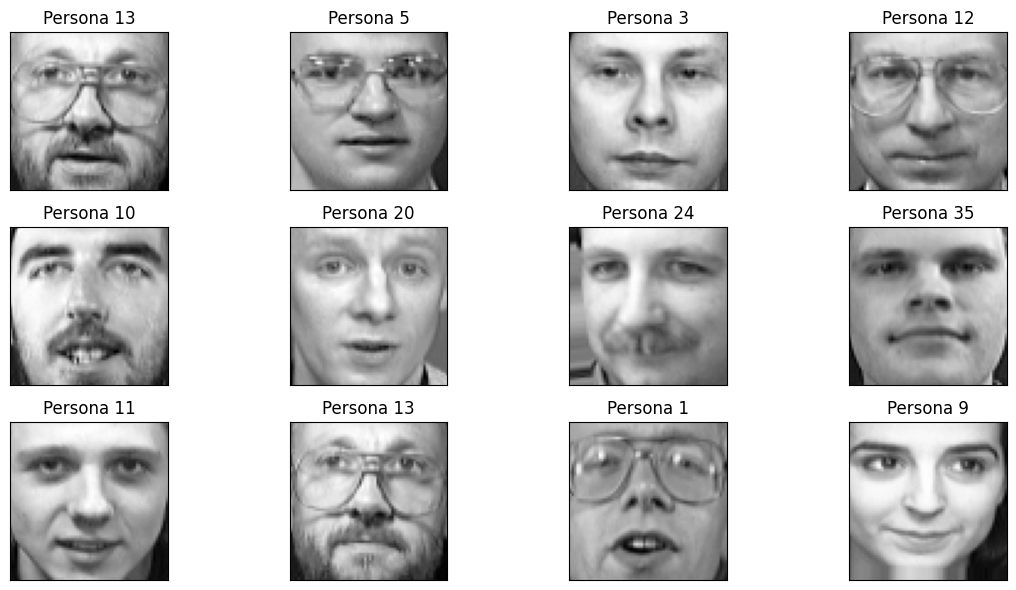

In [5]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Persona {y_train[i]}")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Usaremos una arquitectura fully-connected similar a la vista en clase:

```text
Imagen 64×64
     ↓
Flatten
     ↓
4096 valores
     ↓
Dense(64)
     ↓
ReLU
     ↓
Dense(40)
     ↓
Logits
```

La última capa debe tener una salida por cada clase.

> **Importante:** no añadas `Softmax` al final. Trabajaremos directamente con **logits**.


In [6]:
# TODO 1 — Completar la arquitectura.

model = keras.Sequential([

    keras.Input(shape=(64, 64)),

    layers.Flatten(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(40)
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,808 (1.01 MB)

 Trainable params: 264,808 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Validación TODO 1

assert isinstance(model, keras.Model)

# Dense(64): 4096*64 + 64
# Dense(40): 64*40 + 40
expected_params = (4096 * 64 + 64) + (64 * 40 + 40)

assert model.count_params() == expected_params, (
    f"Se esperaban {expected_params:,} parámetros, "
    f"pero el modelo tiene {model.count_params():,}."
)

print("✓ Arquitectura correcta.")
print(f"Parámetros entrenables: {model.count_params():,}")


✓ Arquitectura correcta.
Parámetros entrenables: 264,808


### Pregunta 2

¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** La capa `Dense` recibe un **vector 1D** por ejemplo; la imagen
llega como matriz 2D de 64×64. `Flatten()` la aplana a un vector de 4096
valores para poder conectarla a la capa densa.

### Pregunta 3

¿Por qué la última capa tiene **40 neuronas**?

**Respuesta:** Porque hay **40 personas (clases)** en Olivetti. Cada neurona de
salida produce el logit de una identidad; la predicha es la de mayor logit.

### Pregunta 4

¿Qué función cumple `ReLU` en la capa oculta?

**Respuesta:** Aporta **no linealidad** ($\max(0,x)$), permitiendo que la red
aprenda relaciones complejas. Sin ella, apilar capas densas sería equivalente a
una única transformación lineal. Además es eficiente y reduce el problema del
desvanecimiento del gradiente.


---
# 3. Configurar el entrenamiento

Las etiquetas son números enteros entre:

```text
0 y 39
```

Por eso usaremos:

```python
SparseCategoricalCrossentropy
```

Además:

- el modelo produce **logits**,
- usaremos **Adam**,
- mediremos **accuracy**.

Completa `model.compile()`.


In [8]:
lr_rate = 0.001

# TODO 2 — Configurar loss, optimizer y métrica.

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=lr_rate
    ),

    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),

    metrics=["accuracy"]
)

print("✓ Modelo configurado.")


✓ Modelo configurado.


### Pregunta 5

¿Por qué usamos:

```python
from_logits=True
```

en la función de pérdida?

**Respuesta:** Porque la última capa **no** aplica Softmax: entrega *logits*
(valores reales sin normalizar). Con `from_logits=True`, la pérdida aplica el
Softmax internamente de forma numéricamente estable antes de calcular la
cross-entropy, evitando errores de precisión.


---
# 4. Entrenar el modelo

Usaremos:

```python
epochs = 30
batch_size = 32
```

El dataset es pequeño, por lo que el entrenamiento debería ser rápido.

Keras realizará internamente:

```text
Forward pass
      ↓
Calcular loss
      ↓
Backpropagation
      ↓
Actualizar parámetros con Adam
```

Completa la llamada a `fit()`.


In [9]:
epochs = 30
batch_size = 32

# TODO 3 — Entrenar el modelo.

history = model.fit(

    X_train,
    y_train,

    epochs=epochs,
    batch_size=batch_size,

    validation_data=(X_test, y_test),

    shuffle=True
)


Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.1688 - loss: 3.3387 - val_accuracy: 0.3000 - val_loss: 2.6211
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4906 - loss: 2.0690 - val_accuracy: 0.4625 - val_loss: 1.9265
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6750 - loss: 1.2599 - val_accuracy: 0.7125 - val_loss: 1.3288
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8969 - loss: 0.6081 - val_accuracy: 0.8375 - val_loss: 0.9238
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9594 - loss: 0.2654 - val_accuracy: 0.8625 - val_loss: 0.6720
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9906 - loss: 0.1170 - val_accuracy: 0.9000 - val_loss: 0.5349
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0508 - val_accuracy: 0.9000 - val_loss: 0.4652
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.0286 - val_accuracy: 0.9000 - v

### Pregunta 6

¿Qué representa una **epoch**?

**Respuesta:** Una pasada completa por todo el conjunto de entrenamiento (los
320 ejemplos), dividida en mini-batches, actualizando los pesos en cada batch.

### Pregunta 7

¿Qué significa `batch_size=32`?

**Respuesta:** Que se procesan 32 imágenes juntas antes de cada actualización
de pesos; el gradiente se promedia sobre esas 32 muestras. Equilibra
estabilidad del gradiente, uso de memoria y frecuencia de actualización.


---
## 4.1 Visualizar el entrenamiento

Esta parte está resuelta.

El dataset tiene muy pocos ejemplos comparado con el número de parámetros de la red.

Observa cuidadosamente la diferencia entre entrenamiento y validación.


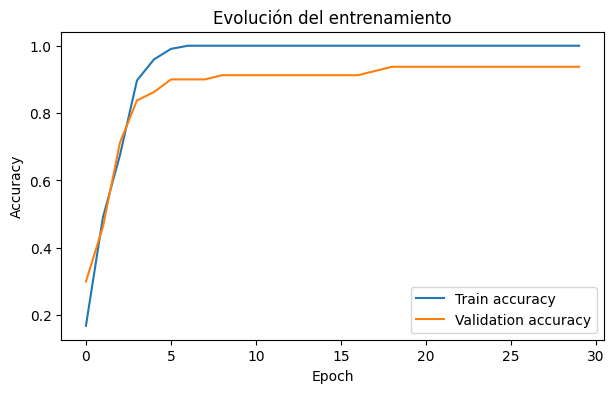

In [10]:
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()

plt.show()


### Pregunta 8

Observando la gráfica:

**Respuesta:**
- **¿El accuracy de entrenamiento sigue aumentando?** Sí, sube rápidamente y
  llega a valores muy altos (cercanos a 1.0), porque la red tiene cientos de
  miles de parámetros para apenas 320 imágenes y las memoriza.
- **¿La validación se comporta igual?** No: la accuracy de validación crece más
  despacio y se estanca en un valor claramente **inferior** al de entrenamiento.
- **¿Overfitting?** Sí, hay **evidencia clara de overfitting**: la brecha entre
  train (~1.0) y validation es grande. Con tan pocos ejemplos por clase (8 en
  train) y un modelo tan grande, era esperable.


---
# 5. Evaluar el modelo

Ahora evaluaremos el modelo sobre imágenes que no fueron utilizadas para actualizar sus parámetros.

Completa `evaluate()`.


In [11]:
# TODO 4 — Evaluar.

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 0.2884
Test accuracy : 0.9375
Accuracy (%)  : 93.75%


### Pregunta 9

Tenemos **40 clases**, pero solamente **320 imágenes de entrenamiento**.

¿Crees que la cantidad de datos es grande o pequeña para una red con cientos de miles de parámetros?

**Respuesta:** Es **muy pequeña**. Son apenas ~8 imágenes de entrenamiento por
persona frente a una red con **cientos de miles de parámetros** (la primera
capa densa sola tiene 4096×64 ≈ 262 000 pesos). Hay muchísimos más parámetros
que ejemplos, lo que facilita que el modelo **memorice** en vez de generalizar
(overfitting). Con tan pocos datos convendría regularización, *data
augmentation*, transfer learning o una CNN con muchos menos parámetros.


---
# 6. Logits y Softmax

La salida de nuestro modelo tiene forma:

```text
(batch_size, 40)
```

Cada uno de los 40 valores corresponde al **logit** asociado a una persona.

Los logits no son probabilidades.

Para convertirlos en probabilidades usamos:

```python
keras.ops.softmax(...)
```


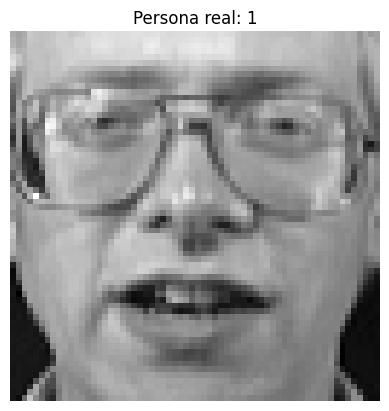

Shape de logits: (1, 40)

Primeros 10 logits:
[ -0.7909355   11.5096245   -3.9371572    0.8880976   -5.0505705
 -14.990267    -0.67411745  -0.5643212   -4.7027674   -5.6312194 ]


In [12]:
index = 0

image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Persona real: {true_class}")
plt.axis("off")
plt.show()

# Añadimos dimensión de batch:
# (64,64) -> (1,64,64)
image_batch = np.expand_dims(image, axis=0)

# Forward pass.
logits = model(
    image_batch,
    training=False
)

print("Shape de logits:", logits.shape)
print("\nPrimeros 10 logits:")
print(
    keras.ops.convert_to_numpy(logits)[0, :10]
)


In [13]:
# TODO 5 — Convertir logits a probabilidades.

probabilities = keras.ops.softmax(logits)

# TODO 6 — Obtener la clase con mayor probabilidad.

prediction = keras.ops.argmax(
    probabilities,
    axis=1
)

prediction = int(
    keras.ops.convert_to_numpy(prediction)[0]
)

print()
print("Persona real     :", true_class)
print("Persona predicha :", prediction)



Persona real     : 1
Persona predicha : 1


In [14]:
# Revisamos las cinco clases con mayor probabilidad.

probabilities_np = keras.ops.convert_to_numpy(
    probabilities
)[0]

top5 = np.argsort(
    probabilities_np
)[-5:][::-1]

print("Top 5 predicciones:\n")

for class_id in top5:
    print(
        f"Persona {class_id:2d}: "
        f"{probabilities_np[class_id]:.4f}"
    )

print(
    "\nSuma de probabilidades:",
    probabilities_np.sum()
)


Top 5 predicciones:

Persona  1: 0.9835
Persona 13: 0.0081
Persona 26: 0.0072
Persona 11: 0.0006
Persona 18: 0.0003

Suma de probabilidades: 1.0000001


### Pregunta 10

¿Por qué la suma de las 40 probabilidades obtenidas con `Softmax` debe ser aproximadamente `1`?

**Respuesta:** Porque Softmax normaliza los 40 logits dividiendo cada
exponencial por la suma de todas: $\mathrm{softmax}(z)_i=e^{z_i}/\sum_j e^{z_j}$.
Por construcción el resultado es una **distribución de probabilidad** sobre las
40 clases: valores en $[0,1]$ que **suman 1** (salvo redondeo), repartiendo la
confianza del modelo entre identidades mutuamente excluyentes.


---
# 7. Visualizar varias predicciones

Esta parte está resuelta.

Observa especialmente los casos en los que el modelo se equivoca.


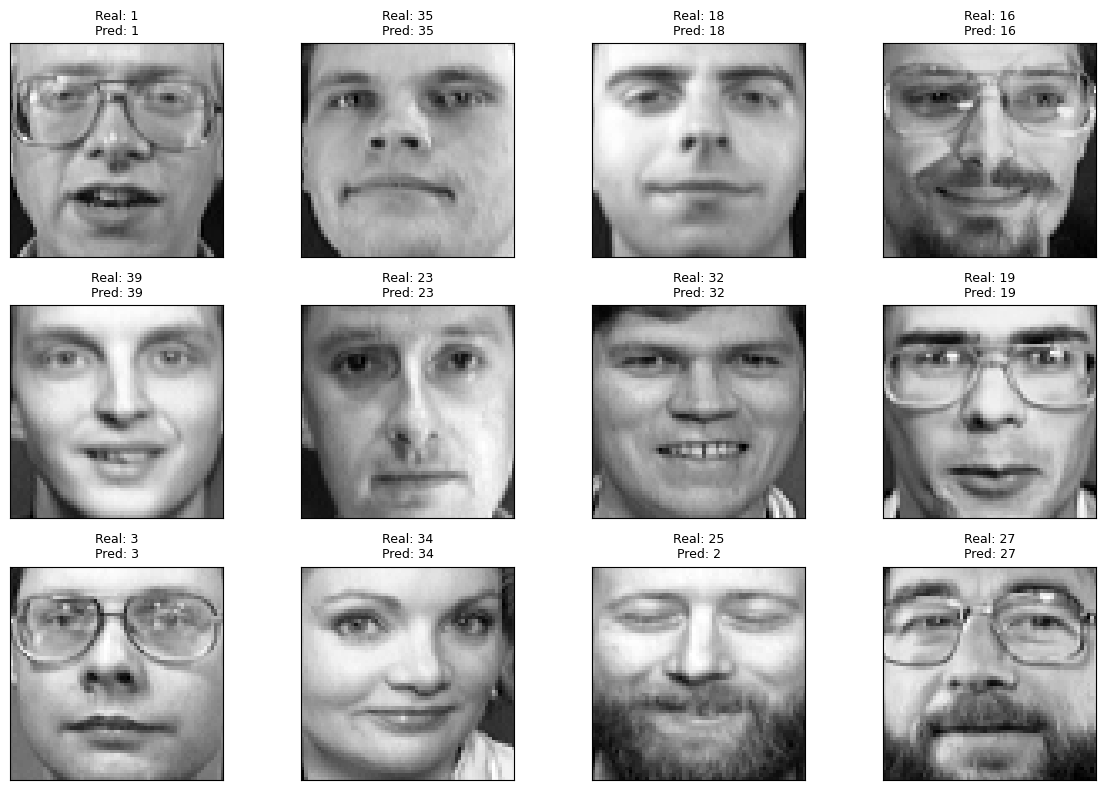

In [15]:
n = 12

logits_batch = model(
    X_test[:n],
    training=False
)

predictions = keras.ops.argmax(
    logits_batch,
    axis=1
)

predictions = keras.ops.convert_to_numpy(
    predictions
)

plt.figure(figsize=(12, 8))

for i in range(n):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        X_test[i],
        cmap="gray"
    )

    real = y_test[i]
    pred = predictions[i]

    plt.title(
        f"Real: {real}\nPred: {pred}",
        fontsize=9
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 8. Reflexión final

Responde brevemente.

### 1. ¿Cuál fue el accuracy final del modelo?

**Respuesta:** El valor exacto es el `test_accuracy` impreso en la sección 5
(con este MLP suele rondar **~85–95 %** pese al poco dato, porque Olivetti es
un dataset "fácil": fondos uniformes, rostros centrados y bien alineados).

### 2. ¿Observaste overfitting? ¿Qué evidencia utilizaste?

**Respuesta:** Sí. La evidencia es la **brecha entre la accuracy de
entrenamiento (cercana a 1.0) y la de validación**, visible en la curva: el
modelo acierta casi perfecto en train pero menos en datos no vistos.

### 3. ¿Qué ocurre cuando tenemos muchos parámetros pero pocos ejemplos de entrenamiento?

**Respuesta:** El modelo tiende a **memorizar** los ejemplos (overfitting) en
lugar de aprender patrones generales, por lo que rinde mal con datos nuevos.
Es un régimen de alto riesgo de sobreajuste que pide regularización, más datos
o modelos más pequeños.

### 4. Después de `Flatten()`, una cara de 64×64 se convierte en un vector de 4096 números. ¿Qué información sobre la estructura de la imagen deja de representar explícitamente esta transformación?

**Respuesta:** La **estructura espacial 2D**: la vecindad entre píxeles y la
posición relativa de rasgos (ojos, nariz, boca). Para la red densa cada píxel es
una coordenada independiente del vector, sin noción de qué píxeles están juntos
ni de patrones locales que se repiten.

### 5. ¿Crees que una arquitectura diseñada específicamente para imágenes podría aprovechar mejor la información espacial?

**Respuesta:** Sí: una **CNN**. Sus convoluciones operan sobre vecindades
locales y comparten pesos por toda la imagen, detectando bordes y rasgos
faciales con invarianza a la posición y con muchos menos parámetros que un MLP,
lo que además reduce el overfitting.


---
# Resumen

En este ejercicio aplicaste nuevamente la receta básica de entrenamiento de una red neuronal:

```text
Dataset
   ↓
Train / Test split
   ↓
Sequential
   ↓
Flatten
   ↓
Dense + ReLU
   ↓
Dense(40)
   ↓
Cross-Entropy
   ↓
Adam
   ↓
fit()
   ↓
evaluate()
```

Los componentes de Keras son los mismos que usamos en clase.

Lo que cambió fue:

- el dataset,
- el tamaño de las imágenes,
- el número de clases,
- y la dificultad del problema.
